# Project Phase 3 — Machine Learning for Anomaly Detection

*K-Means Clustering on Healthy Data*

**Course:** CIV E 789 Sensing Techniques and Data Analytics (Fall 2026)  
**Instructor:** Mohammad Talebi-Kalaleh, Ph.D.  
**Group:** 6 (sensors S2, S4, S6, S9, S12, S15, S18, S21, S24)  
**Data:** `phase3_modal_data.json` (intact: 200 estimates; damage1 and damage2: 50 estimates each)

**Members:**

| Member | CCID |
|---|---|
| Amilcar Diaz | `adiazgar` |
| Alexander Jordan | `ajordan2` |

## Contents

0. [Setup](#setup)
1. [Part A: Concept Questions](#part-a)
    - [A1. K-Means by Hand (5 pts)](#a1)
    - [A2. Feature Scaling (4 pts)](#a2)
    - [A3. Fit, Calibration and Test Records (4 pts)](#a3)
    - [A4. One Cluster and the Phase 2 Methods (4 pts)](#a4)
    - [A5. Several Normal States (4 pts)](#a5)
    - [A6. Limits of K-Means (4 pts)](#a6)
2. [Part B: K-Means Anomaly Detector](#part-b)
    - [B1. Data Preparation (8 pts)](#b1)
    - [B2. Clustering the Healthy Baseline and Choosing $k$ (12 pts)](#b2)
    - [B3. Anomaly Score and Threshold (10 pts)](#b3)
    - [B4. Performance Evaluation (10 pts)](#b4)
    - [B5. Effect of the Number of Clusters (12 pts)](#b5)
    - [B6. Damage Severity (8 pts)](#b6)
3. [Part C: Engineering Insights](#part-c)
    - [C1. Detector Recommendation (5 pts)](#c1)
    - [C2. From Simulation to the Field (5 pts)](#c2)
    - [C3. A Bridge with Several Normal States (5 pts)](#c3)
4. [Use of Generative AI](#ai-note)

<a id="setup"></a>
## 0. Setup

In [1]:
# Google Colab only: put here the code that mounts Google Drive and sets the project folder

Esta sección carga las librerías y define lo que usan todas las partes:

- `GROUP = 6`: elige nuestros nueve sensores y es la semilla de la división de los registros sanos.
- `RANDOM_STATE = 0`: semilla fija de `KMeans`, para que cada ejecución dé los mismos clusters.
- Las figuras se guardan en `figures/part-b/` y las tablas en `results/` (CSV).
- `show_table` pone el título de la tabla arriba (**Table N.**) y `show_figure` pone el pie de la figura abajo (**Figure N.**), ambos fuera del objeto.
- `COLORS`: un color fijo para cada grupo de registros (sanos, damage1 y damage2), el mismo en todas las figuras.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Starter code provided with the assignment (same folder as this notebook)
from phase3_kmeans_starter import SENSOR_GROUPS, load_modal_data, split_healthy, build_features

# Our group number: it selects our nine sensors and is the seed of the data split
GROUP = 6

# Fixed random state for KMeans, so that every run gives the same clusters
RANDOM_STATE = 0

# Output folders (created if they do not exist)
FIG_DIR = Path('figures')
RES_DIR = Path('results')
(FIG_DIR / 'part-b').mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

# One fixed color per group of records, used in every figure
COLORS = {'healthy': '#2a78d6', 'damage1': '#eb6834', 'damage2': '#1baf7a'}


def show_table(df, number, caption, filename=None, precision=3):
    """Show the caption above the table; optionally save the table as CSV in results/."""
    display(Markdown(f'**Table {number}.** {caption}'))
    display(df.style.format(precision=precision, na_rep='–'))
    if filename is not None:
        df.to_csv(RES_DIR / filename)


def show_figure(fig, number, caption, filename, part='part-b'):
    """Save the figure in figures/<part>/, show it and put the caption below it."""
    fig.savefig(FIG_DIR / part / filename, dpi=300, bbox_inches='tight')
    display(fig)
    plt.close(fig)
    display(Markdown(f'**Figure {number}.** {caption}'))

<a id="part-a"></a>
## Part A: Concept Questions (25 pts)

<a id="a1"></a>
### A1. K-Means by Hand (5 pts)

<a id="a2"></a>
### A2. Feature Scaling (4 pts)

<a id="a3"></a>
### A3. Fit, Calibration and Test Records (4 pts)

<a id="a4"></a>
### A4. One Cluster and the Phase 2 Methods (4 pts)

<a id="a5"></a>
### A5. Several Normal States (4 pts)

<a id="a6"></a>
### A6. Limits of K-Means (4 pts)

<a id="part-b"></a>
## Part B: K-Means Anomaly Detector (60 pts)

En esta parte se construyen dos detectores de anomalías con k-means, entrenados solo con registros sanos:

- **Detector F:** las tres frecuencias naturales ($f_1, f_2, f_3$).
- **Detector FM:** las tres frecuencias y los tres MAC ($f_1, f_2, f_3, \mathrm{MAC}_1, \mathrm{MAC}_2, \mathrm{MAC}_3$).

Se sigue el procedimiento visto en clase (Lecture 6, *Fit the whole pipeline on healthy records*): dividir los registros sanos, estandarizar, agrupar con k-means, puntuar cada registro por su distancia al centroide sano más cercano y calibrar un umbral. Los registros dañados solo se usan al final, para probar el detector terminado.

<a id="b1"></a>
### B1. Data Preparation (8 pts)

**Carga y división de los datos.** El código de inicio del profesor (`phase3_kmeans_starter.py`) carga las frecuencias y las formas modales solo en nuestros nueve sensores. Luego divide los 200 registros sanos una sola vez, al azar, con la semilla 6 (nuestro número de grupo). Cada subconjunto tiene un papel distinto (Table 1):

- **Fit (100):** con ellos se ajusta todo: el escalador, la forma modal de referencia del MAC y los centroides.
- **Calibration (50):** solo sirven para fijar el umbral de alarma.
- **Test (50):** registros sanos que el detector nunca vio; miden las falsas alarmas.

Los 50 registros de cada escenario de daño no se usan para ajustar nada; solo para probar el detector.

In [3]:
# Step 1: load the frequencies and the mode shapes at our nine sensors
sensors = SENSOR_GROUPS[GROUP]
data = load_modal_data('phase3_modal_data.json', sensors)

# Step 2: split the 200 healthy records once: 100 fit, 50 calibration, 50 test (seed = group number)
n_healthy = len(data['intact']['freq'])
fit_idx, cal_idx, test_idx = split_healthy(n_healthy, seed=GROUP)

# Step 3: table with the size and the use of each subset
sensor_names = ''
for s in sensors:
    sensor_names = sensor_names + 'S' + str(s) + ' '

subsets_table = pd.DataFrame({
    'Records': [len(fit_idx), len(cal_idx), len(test_idx),
                len(data['damage1']['freq']), len(data['damage2']['freq'])],
    'Use': ['Fit the scaler, the MAC reference and k-means',
            'Set the threshold',
            'Healthy test records',
            'Test only',
            'Test only'],
}, index=pd.Index(['Intact: fit', 'Intact: calibration', 'Intact: test', 'Damage1', 'Damage2'],
                  name='Subset'))

show_table(subsets_table, 1, f'Subsets of records. Group {GROUP} sensors: {sensor_names.strip()}.')

**Table 1.** Subsets of records. Group 6 sensors: S2 S4 S6 S9 S12 S15 S18 S21 S24.

,Records,Use
Subset,,
Intact: fit,100,"Fit the scaler, the MAC reference and k-means"
Intact: calibration,50,Set the threshold
Intact: test,50,Healthy test records
Damage1,50,Test only
Damage2,50,Test only


**Matriz de características.** Cada registro se resume en seis números: $f_1$, $f_2$, $f_3$ y el MAC de cada modo. El MAC compara la forma modal del registro con una forma de referencia (Ec. 1):

$$\mathrm{MAC}_r = \frac{\left(\boldsymbol{\phi}_{\mathrm{ref},r}^{T}\,\boldsymbol{\phi}_{r}\right)^2}{\left(\boldsymbol{\phi}_{\mathrm{ref},r}^{T}\,\boldsymbol{\phi}_{\mathrm{ref},r}\right)\left(\boldsymbol{\phi}_{r}^{T}\,\boldsymbol{\phi}_{r}\right)} \tag{1}$$

- $\boldsymbol{\phi}_{r}$: forma del modo $r$ del registro, en los 9 sensores.
- $\boldsymbol{\phi}_{\mathrm{ref},r}$: forma de referencia del modo $r$, que es el promedio de las formas de los 100 registros *fit*.
- $\mathrm{MAC}_r = 1$ si las dos formas son iguales (sin importar la escala); baja cuando la forma cambia.

La función `build_features` del código de inicio calcula la Ec. 1 y arma una matriz con una fila por registro y una columna por característica, en el orden $f_1, f_2, f_3, \mathrm{MAC}_1, \mathrm{MAC}_2, \mathrm{MAC}_3$.

In [4]:
# Six features per record: f1, f2, f3, MAC1, MAC2, MAC3
# (MAC reference = mean mode shapes of the healthy fit records, Eq. 1)
X = build_features(data, fit_idx)

# Feature matrix of each subset
X_fit = X['intact'][fit_idx]
X_cal = X['intact'][cal_idx]
X_test = X['intact'][test_idx]
X_d1 = X['damage1']
X_d2 = X['damage2']

print('Intact  feature matrix:', X['intact'].shape)
print('Damage1 feature matrix:', X_d1.shape)
print('Damage2 feature matrix:', X_d2.shape)

Intact  feature matrix: (200, 6)
Damage1 feature matrix: (50, 6)
Damage2 feature matrix: (50, 6)


**Estadísticas de cada característica.** La Table 2 da la media y la desviación estándar de cada característica en los registros *fit*, damage1 y damage2. Los MAC sanos difieren de 1 solo en la cuarta o quinta cifra decimal, así que se reportan como $1-\mathrm{MAC}$ en notación científica. La desviación estándar es la poblacional (se divide entre $N$), la misma que usa `StandardScaler` en el paso siguiente.

In [5]:
# Rows of the table: the three frequencies and 1 - MAC of the three modes
row_names = ['f1 (Hz)', 'f2 (Hz)', 'f3 (Hz)', '1 - MAC1', '1 - MAC2', '1 - MAC3']
groups = {'Fit': X_fit, 'Damage1': X_d1, 'Damage2': X_d2}

stats_table = pd.DataFrame(index=pd.Index(row_names, name='Feature'))
for group_name in groups:
    values = groups[group_name].copy()
    values[:, 3:] = 1 - values[:, 3:]          # MAC columns (3, 4, 5) reported as 1 - MAC

    means = np.mean(values, axis=0)
    stds = np.std(values, axis=0)              # population std (ddof = 0), as in StandardScaler

    # Frequencies with 4 decimals, 1 - MAC in scientific notation
    mean_text = []
    std_text = []
    for j in range(6):
        if j < 3:
            mean_text.append(f'{means[j]:.4f}')
            std_text.append(f'{stds[j]:.4f}')
        else:
            mean_text.append(f'{means[j]:.2e}')
            std_text.append(f'{stds[j]:.2e}')

    stats_table[group_name + ' mean'] = mean_text
    stats_table[group_name + ' std'] = std_text

show_table(stats_table, 2, 'Mean and standard deviation of each feature for the healthy fit records, '
           'damage1 and damage2. MAC values reported as 1 - MAC.', 'B1_feature_statistics.csv')

**Table 2.** Mean and standard deviation of each feature for the healthy fit records, damage1 and damage2. MAC values reported as 1 - MAC.

,Fit mean,Fit std,Damage1 mean,Damage1 std,Damage2 mean,Damage2 std
Feature,,,,,,
f1 (Hz),1.1695,0.0429,1.1547,0.0403,1.1101,0.0582
f2 (Hz),3.0843,0.1117,2.9845,0.1056,2.6320,0.1359
f3 (Hz),4.4467,0.1642,4.3735,0.1549,4.2222,0.2236
1 - MAC1,1.98e-05,1.75e-05,1.07e-04,6.02e-05,2.82e-03,5.02e-04
1 - MAC2,1.17e-04,1.22e-04,1.89e-03,7.12e-04,3.32e-02,3.88e-03
1 - MAC3,1.62e-04,1.39e-04,1.67e-03,6.52e-04,3.43e-02,3.96e-03


**Estandarización.** Las frecuencias están en Hz y se dispersan unas centésimas; los MAC no tienen unidades y se dispersan del orden de $10^{-5}$ a $10^{-4}$ (Table 2). k-means trabaja con distancias, así que sin escalar solo vería las frecuencias. Por eso cada característica se lleva a la misma escala con la media y la desviación estándar de los registros *fit* (Ec. 2; Lecture 5, *Rows are occasions; columns are features*):

$$z_{ij} = \frac{x_{ij}-\mu_j}{\sigma_j} \tag{2}$$

- $x_{ij}$: característica $j$ del registro $i$.
- $\mu_j$, $\sigma_j$: media y desviación estándar de la característica $j$ en los 100 registros *fit*.
- $z_{ij}$: cuántas desviaciones estándar sanas se aleja el registro de la media sana.

Se ajusta un `StandardScaler` por detector (3 columnas para F y 6 para FM) **solo con los registros *fit*** y luego se aplica, sin cambiarlo, a todos los demás. Así ningún registro de calibración, test o daño influye en la escala. Después de escalar, los registros *fit* quedan con media 0 y desviación estándar 1.

In [6]:
# Columns used by each detector
COLS_F = [0, 1, 2]                 # f1, f2, f3
COLS_FM = [0, 1, 2, 3, 4, 5]       # f1, f2, f3, MAC1, MAC2, MAC3

# All the subsets, by name
subsets = {'fit': X_fit, 'calibration': X_cal, 'test': X_test, 'damage1': X_d1, 'damage2': X_d2}

# Step 1: fit one scaler per detector with the healthy fit records only (Eq. 2)
scaler_F = StandardScaler().fit(X_fit[:, COLS_F])
scaler_FM = StandardScaler().fit(X_fit[:, COLS_FM])

# Step 2: apply the same scalers to every subset
Z_F = {}
Z_FM = {}
for name in subsets:
    Z_F[name] = scaler_F.transform(subsets[name][:, COLS_F])
    Z_FM[name] = scaler_FM.transform(subsets[name][:, COLS_FM])

# Check: the fit records now have mean 0 and standard deviation 1
print('Detector FM, fit records after scaling')
print('  mean of each feature:', np.round(np.mean(Z_FM['fit'], axis=0), 3) + 0.0)
print('  std of each feature: ', np.round(np.std(Z_FM['fit'], axis=0), 3))

Detector FM, fit records after scaling
  mean of each feature: [0. 0. 0. 0. 0. 0.]
  std of each feature:  [1. 1. 1. 1. 1. 1.]


**Gráficas de dispersión.** La Figure 1 muestra $f_1$ contra $f_2$ (en Hz) y $1-\mathrm{MAC}_1$ contra $1-\mathrm{MAC}_2$ en ejes logarítmicos, porque esos valores cubren varios órdenes de magnitud. El coeficiente de correlación entre $f_1$ y $f_2$ de los registros *fit* es (Ec. 3):

$$\rho_{12} = \frac{\sum_{i=1}^{N}\left(f_{1,i}-\bar{f}_1\right)\left(f_{2,i}-\bar{f}_2\right)}{\sqrt{\sum_{i=1}^{N}\left(f_{1,i}-\bar{f}_1\right)^2}\,\sqrt{\sum_{i=1}^{N}\left(f_{2,i}-\bar{f}_2\right)^2}} \tag{3}$$

- $f_{1,i}$, $f_{2,i}$: primera y segunda frecuencia del registro $i$; $\bar{f}_1$, $\bar{f}_2$: sus medias.
- $N = 100$ registros *fit*.
- $\rho_{12}$ va de −1 a 1; cerca de 1 significa que $f_1$ y $f_2$ suben y bajan juntas.

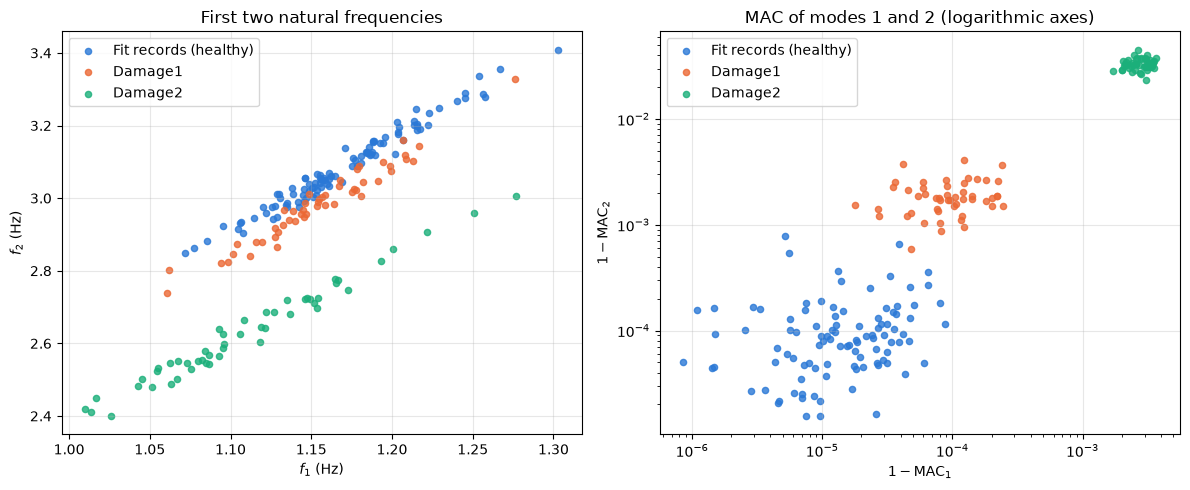

**Figure 1.** Healthy fit records, damage1 and damage2: $f_1$ versus $f_2$ (left) and $1-\mathrm{MAC}_1$ versus $1-\mathrm{MAC}_2$ on logarithmic axes (right).

Correlation coefficient between f1 and f2 (fit records): rho = 0.985


In [7]:
# Groups to plot: label, feature matrix and color
plot_groups = [('Fit records (healthy)', X_fit, COLORS['healthy']),
               ('Damage1', X_d1, COLORS['damage1']),
               ('Damage2', X_d2, COLORS['damage2'])]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label, values, color in plot_groups:
    # Left: f1 versus f2, in Hz
    axes[0].scatter(values[:, 0], values[:, 1], s=20, color=color, alpha=0.8, label=label)
    # Right: 1 - MAC1 versus 1 - MAC2, on logarithmic axes
    axes[1].scatter(1 - values[:, 3], 1 - values[:, 4], s=20, color=color, alpha=0.8, label=label)

axes[0].set_xlabel('$f_1$ (Hz)')
axes[0].set_ylabel('$f_2$ (Hz)')
axes[0].set_title('First two natural frequencies')

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('$1 - \\mathrm{MAC}_1$')
axes[1].set_ylabel('$1 - \\mathrm{MAC}_2$')
axes[1].set_title('MAC of modes 1 and 2 (logarithmic axes)')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
show_figure(fig, 1, 'Healthy fit records, damage1 and damage2: $f_1$ versus $f_2$ (left) and '
            '$1-\\mathrm{MAC}_1$ versus $1-\\mathrm{MAC}_2$ on logarithmic axes (right).',
            'B1_scatter_f1_f2_mac.png')

# Correlation coefficient between f1 and f2 of the fit records (Eq. 3)
rho_f1_f2 = np.corrcoef(X_fit[:, 0], X_fit[:, 1])[0, 1]
print(f'Correlation coefficient between f1 and f2 (fit records): rho = {rho_f1_f2:.3f}')

**Discusión.**

- **Frecuencias.** Las tres bajan con el daño (Table 2). En damage1 la caída es pequeña: −1.3 % en $f_1$, −3.2 % en $f_2$ y −1.6 % en $f_3$, del mismo orden que la dispersión sana. En damage2 es mayor: −5.1 %, −14.7 % y −5.1 %. En la Figure 1, damage1 queda pegado a la nube sana, apenas por debajo de ella; damage2 forma una nube aparte, más abajo.
- **MAC.** $1-\mathrm{MAC}$ crece con el daño en los tres modos; en el modo 2 pasa de $1.2\times10^{-4}$ (sanos) a $1.9\times10^{-3}$ (damage1) y $3.3\times10^{-2}$ (damage2). Como los MAC sanos casi no varían (desviación estándar de $10^{-5}$ a $10^{-4}$), incluso el cambio de damage1 se separa claramente de los sanos en la Figure 1.
- **Correlación.** $\rho_{12} = 0.985$: las frecuencias sanas suben y bajan juntas y forman una nube alargada, casi una línea, como si un mismo factor (por ejemplo, un cambio pequeño de rigidez o de masa de todo el puente) las moviera a la vez.
- **Escenario más difícil de detectar:** damage1, sobre todo si solo se usan las frecuencias, porque sus cambios se confunden con la variación sana. Con los MAC, incluso damage1 se distingue.

<a id="b2"></a>
### B2. Clustering the Healthy Baseline and Choosing $k$ (12 pts)

**Cómo agrupa k-means.** k-means coloca $k$ centroides y repite dos pasos hasta que nada se mueve (Lecture 6, *Clustering finds groups without labels*): (1) asigna cada registro a su centroide más cercano y (2) mueve cada centroide al promedio de sus registros. No usa etiquetas: los grupos salen solo de las distancias entre registros. Cada repetición baja la suma de cuadrados dentro de los clusters (Ec. 4):

$$J = \sum_{i=1}^{N}\,\min_{j=1,\dots,k}\left\lVert \mathbf{z}_i-\mathbf{c}_j\right\rVert^2 \tag{4}$$

- $\mathbf{z}_i$: registro $i$ estandarizado (Ec. 2); $N = 100$ registros *fit*.
- $\mathbf{c}_j$: centroide del cluster $j$.
- $J$: en scikit-learn es `inertia_` (*within-cluster sum of squares*, WCSS).

El resultado depende de dónde arrancan los centroides. Por eso `n_init = 20` corre k-means desde 20 inicios distintos y se queda con el de menor $J$; `random_state = 0` fija esos inicios para que el resultado se pueda repetir.

**Cómo se elige $k$ (solo con registros sanos).** Se ajusta k-means a los 100 registros *fit* estandarizados para $k = 1, \dots, 8$ y se miran dos curvas:

- **Codo (*elbow*):** $J$ como porcentaje de su valor con $k = 1$ (Ec. 5). $J$ siempre baja al agregar clusters; lo que se busca es un codo, el punto a partir del cual deja de bajar mucho.

$$J_{\%}(k) = 100\,\frac{J(k)}{J(1)} \tag{5}$$

- **Silueta (*silhouette*):** mide si cada registro está más cerca de su propio cluster que del cluster vecino (Ec. 6). Solo existe para $k \geq 2$, y se reporta el promedio de los $N$ registros.

$$s_i = \frac{b_i-a_i}{\max\left(a_i,\,b_i\right)} \tag{6}$$

- $a_i$: distancia media del registro $i$ a los demás registros de su cluster.
- $b_i$: distancia media del registro $i$ a los registros del cluster vecino más cercano.
- $s_i$ cerca de 1: grupos bien separados; cerca de 0: el registro está en la frontera entre dos clusters.

In [8]:
K_VALUES = [1, 2, 3, 4, 5, 6, 7, 8]

# Standardized records of each detector
detectors = {'F': Z_F, 'FM': Z_FM}

# Results for each detector: J as % of k = 1 (Eq. 5) and mean silhouette (Eq. 6)
wcss_percent = {'F': [], 'FM': []}
silhouette = {'F': [], 'FM': []}

for det in detectors:
    Z_fit = detectors[det]['fit']
    for k in K_VALUES:
        kmeans = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z_fit)

        # Within-cluster sum of squares (Eq. 4), as a percentage of its k = 1 value (Eq. 5)
        if k == 1:
            wcss_k1 = kmeans.inertia_
        wcss_percent[det].append(100 * kmeans.inertia_ / wcss_k1)

        # Mean silhouette coefficient (Eq. 6); not defined for a single cluster
        if k == 1:
            silhouette[det].append(np.nan)
        else:
            silhouette[det].append(silhouette_score(Z_fit, kmeans.labels_))

elbow_table = pd.DataFrame({
    'F: J (% of k = 1)': wcss_percent['F'],
    'F: silhouette': silhouette['F'],
    'FM: J (% of k = 1)': wcss_percent['FM'],
    'FM: silhouette': silhouette['FM'],
}, index=pd.Index(K_VALUES, name='k'))

show_table(elbow_table, 3, 'Within-cluster sum of squares as a percentage of its k = 1 value and mean '
           'silhouette coefficient of the healthy fit records, for k = 1 to 8.', 'B2_elbow_silhouette.csv')

**Table 3.** Within-cluster sum of squares as a percentage of its k = 1 value and mean silhouette coefficient of the healthy fit records, for k = 1 to 8.

,F: J (% of k = 1),F: silhouette,FM: J (% of k = 1),FM: silhouette
k,,,,
1,100.000,–,100.000,–
2,33.806,0.583,66.742,0.328
3,20.468,0.553,49.981,0.343
4,10.850,0.544,42.316,0.342
5,7.391,0.541,35.590,0.318
6,5.220,0.516,30.091,0.280
7,3.964,0.518,26.673,0.275
8,3.082,0.518,23.754,0.278


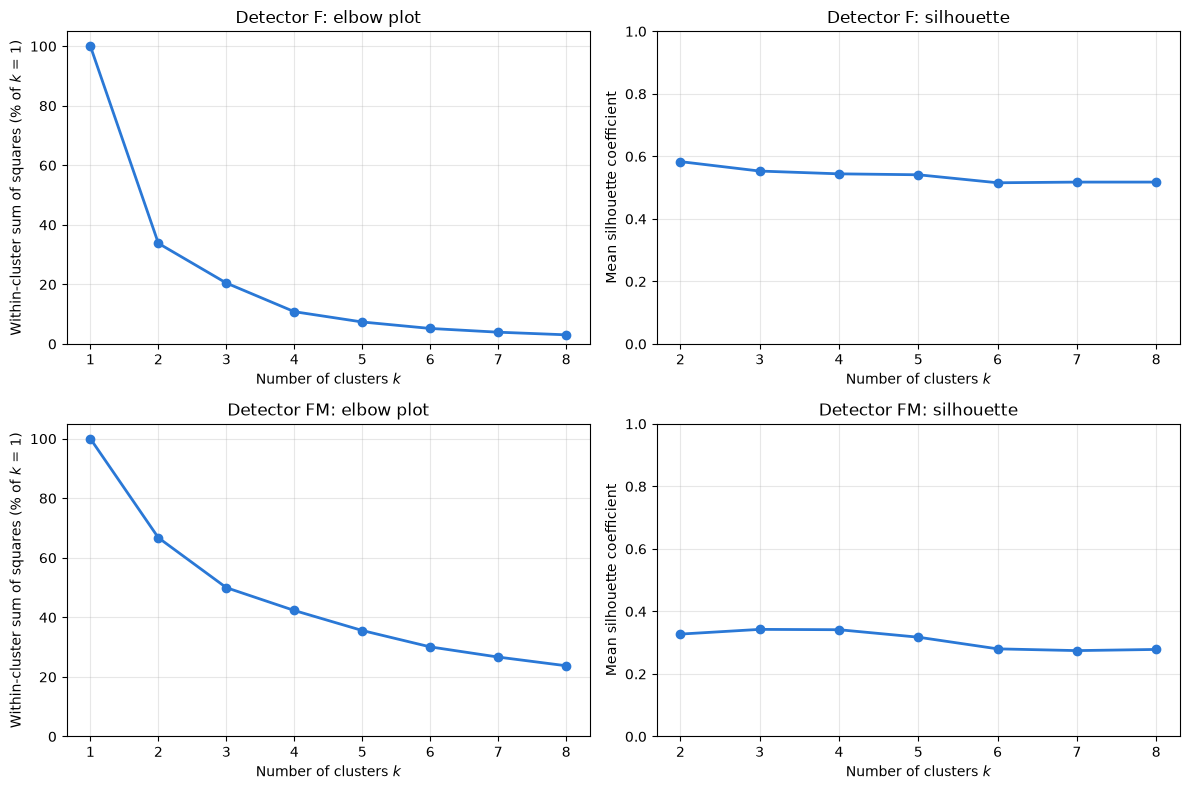

**Figure 2.** Elbow plot (left) and mean silhouette coefficient (right) of the healthy fit records, for Detector F (top) and Detector FM (bottom).

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

row = 0
for det in detectors:
    # Left column: elbow plot (Eq. 5)
    ax = axes[row, 0]
    ax.plot(K_VALUES, wcss_percent[det], marker='o', color=COLORS['healthy'], linewidth=2)
    ax.set_xlabel('Number of clusters $k$')
    ax.set_ylabel('Within-cluster sum of squares (% of $k$ = 1)')
    ax.set_title(f'Detector {det}: elbow plot')
    ax.set_xticks(K_VALUES)
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3)

    # Right column: mean silhouette coefficient for k = 2 to 8 (Eq. 6)
    ax = axes[row, 1]
    ax.plot(K_VALUES[1:], silhouette[det][1:], marker='o', color=COLORS['healthy'], linewidth=2)
    ax.set_xlabel('Number of clusters $k$')
    ax.set_ylabel('Mean silhouette coefficient')
    ax.set_title(f'Detector {det}: silhouette')
    ax.set_xticks(K_VALUES[1:])
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

    row = row + 1

fig.tight_layout()
show_figure(fig, 2, 'Elbow plot (left) and mean silhouette coefficient (right) of the healthy fit records, '
            'for Detector F (top) and Detector FM (bottom).', 'B2_elbow_silhouette.png')

**Elección de $k$ (Table 3, Figure 2).**

- **Detector F.** $J$ cae a 34 % con $k = 2$, lo que parece un codo. Pero la Figure 1 muestra una sola nube alargada ($\rho_{12} = 0.985$), sin grupos separados, y una nube así también da una gran caída en $k = 2$: si una nube gaussiana alargada (casi una línea) se corta en dos mitades, $J$ baja a cerca de $1-2/\pi \approx 36\,\%$, prácticamente lo obtenido. Después, $J$ sigue bajando de forma suave (20 %, 11 %, 7 %, …) sin otro quiebre, y la silueta se mantiene casi plana entre 0.52 y 0.58, sin un máximo claro. Los clusters serían rebanadas de la misma nube, no estados normales distintos.
- **Detector FM.** No hay codo: $J$ baja de forma gradual (67 %, 50 %, 42 %, …) y la silueta es baja (0.27 a 0.34), señal de que los registros no forman grupos separados.
- **Conclusión:** en los dos detectores los registros sanos forman un solo estado normal. Se elige **$k = 1$** para F y para FM. Con $k = 1$ el único centroide es la media de los registros *fit*, es decir, el origen del espacio estandarizado.

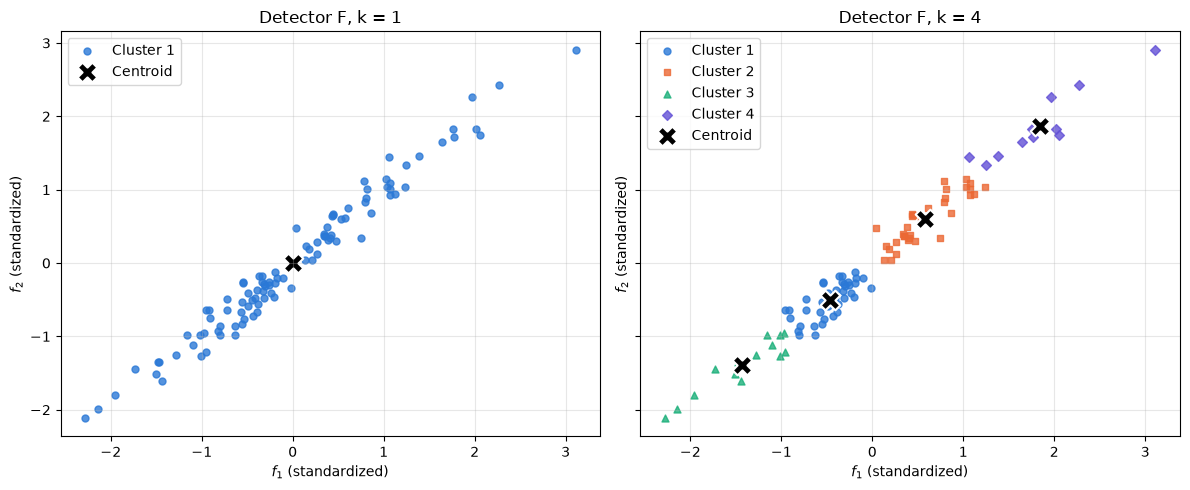

**Figure 3.** Detector F: standardized healthy fit records in the $f_1$-$f_2$ plane, colored by cluster, with the centroids marked, for the chosen k = 1 (left) and k = 4 (right).

In [10]:
# Number of clusters chosen for each detector from the healthy-only plots
K_CHOSEN = {'F': 1, 'FM': 1}

# Detector F: clusters of the standardized fit records seen in the f1-f2 plane
CLUSTER_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#6250d6']
CLUSTER_MARKERS = ['o', 's', '^', 'D']

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

k_to_plot = [K_CHOSEN['F'], 4]
for n in range(2):
    k = k_to_plot[n]
    ax = axes[n]
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z_F['fit'])

    # Records of each cluster (column 0 = f1, column 1 = f2, both standardized)
    for j in range(k):
        in_cluster = kmeans.labels_ == j
        ax.scatter(Z_F['fit'][in_cluster, 0], Z_F['fit'][in_cluster, 1], s=25,
                   color=CLUSTER_COLORS[j], marker=CLUSTER_MARKERS[j], alpha=0.8,
                   label=f'Cluster {j + 1}')

    # Centroids
    ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=200, marker='X',
               color='black', edgecolor='white', linewidth=1.5, label='Centroid')

    ax.set_xlabel('$f_1$ (standardized)')
    ax.set_ylabel('$f_2$ (standardized)')
    ax.set_title(f'Detector F, k = {k}')
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
show_figure(fig, 3, 'Detector F: standardized healthy fit records in the $f_1$-$f_2$ plane, colored by '
            'cluster, with the centroids marked, for the chosen k = 1 (left) and k = 4 (right).',
            'B2_clusters_f1_f2.png')

En la Figure 3, con $k = 1$ el centroide queda en el centro de la nube. Con $k = 4$, k-means corta la nube a lo largo de su eje en cuatro tramos y los centroides quedan sobre la línea de la correlación. Los cuatro clusters no están separados entre sí: son divisiones artificiales de un mismo estado, lo que confirma la elección de $k = 1$.

<a id="b3"></a>
### B3. Anomaly Score and Threshold (10 pts)

**Puntaje de anomalía.** Cada registro se puntúa con su distancia, en el espacio estandarizado, al centroide sano más cercano (Ec. 7; Lecture 6, *Healthy data can have several normal states*):

$$s(\mathbf{x}) = \min_{j=1,\dots,k}\left\lVert \mathbf{z}-\mathbf{c}_j\right\rVert \tag{7}$$

- $\mathbf{z}$: el registro $\mathbf{x}$ estandarizado con el escalador de los registros *fit* (Ec. 2).
- $\mathbf{c}_j$: centroides de k-means ajustados con los registros *fit*.
- $\lVert\cdot\rVert$: distancia euclidiana. Un puntaje grande significa que el registro está lejos de todo lo sano que el detector conoce.

En el código, `kmeans.transform` da la distancia de cada registro a cada centroide (una columna por centroide) y `np.min(..., axis=1)` se queda con la menor.

**Umbral.** El umbral $\tau$ es el percentil 99 de los puntajes de los 50 registros de calibración (Ec. 8; Lecture 6, *Choose k and the threshold using healthy records only*):

$$\tau = Q_{0.99}\left(\left\{s(\mathbf{x}_i)\right\}_{i\,\in\,\text{calibration}}\right) \tag{8}$$

Un registro se clasifica como anomalía si $s(\mathbf{x}) > \tau$. Se usan registros de calibración, y no los *fit*, porque los *fit* están más cerca de sus propios centroides (los centroides se ajustaron con ellos) y darían un umbral demasiado bajo.

In [11]:
def anomaly_score(kmeans, Z):
    """Distance from every standardized record to its nearest centroid (Eq. 7)."""
    distances = kmeans.transform(Z)          # shape (n_records, k): distance to every centroid
    return np.min(distances, axis=1)         # keep the nearest one


# Final k-means model of each detector, with the chosen k
kmeans_final = {}
scores = {'F': {}, 'FM': {}}
tau = {}

for det in detectors:
    Z = detectors[det]
    kmeans_final[det] = KMeans(n_clusters=K_CHOSEN[det], n_init=20,
                               random_state=RANDOM_STATE).fit(Z['fit'])

    # Score of every record of every subset
    for name in Z:
        scores[det][name] = anomaly_score(kmeans_final[det], Z[name])

    # Threshold: 99th percentile of the 50 calibration scores (Eq. 8)
    tau[det] = np.percentile(scores[det]['calibration'], 99)

# Threshold and false alarms on the 50 healthy test records
threshold_rows = []
for det in detectors:
    cal_sorted = np.sort(scores[det]['calibration'])
    n_false_alarms = np.sum(scores[det]['test'] > tau[det])
    n_test = len(scores[det]['test'])
    threshold_rows.append({
        'Detector': det,
        'k': K_CHOSEN[det],
        'Threshold tau': tau[det],
        'Largest calibration score': cal_sorted[-1],
        'Second largest calibration score': cal_sorted[-2],
        'False alarms (of 50 test)': n_false_alarms,
        'False-alarm rate (%)': 100 * n_false_alarms / n_test,
    })

threshold_table = pd.DataFrame(threshold_rows).set_index('Detector')
show_table(threshold_table, 4, 'Threshold (99th percentile of the 50 calibration scores), the two largest '
           'calibration scores and false alarms on the 50 healthy test records.',
           'B3_threshold_false_alarms.csv')

**Table 4.** Threshold (99th percentile of the 50 calibration scores), the two largest calibration scores and false alarms on the 50 healthy test records.

,k,Threshold tau,Largest calibration score,Second largest calibration score,False alarms (of 50 test),False-alarm rate (%)
Detector,,,,,,
F,1,3.230,3.513,2.936,3,6.000
FM,1,6.977,7.751,6.171,1,2.000


La Figure 4 muestra los histogramas de los puntajes con el umbral. En la fila FM los puntajes van de menos de 1 a varios cientos, así que el eje de puntajes es logarítmico; en la fila F caben en un eje lineal.

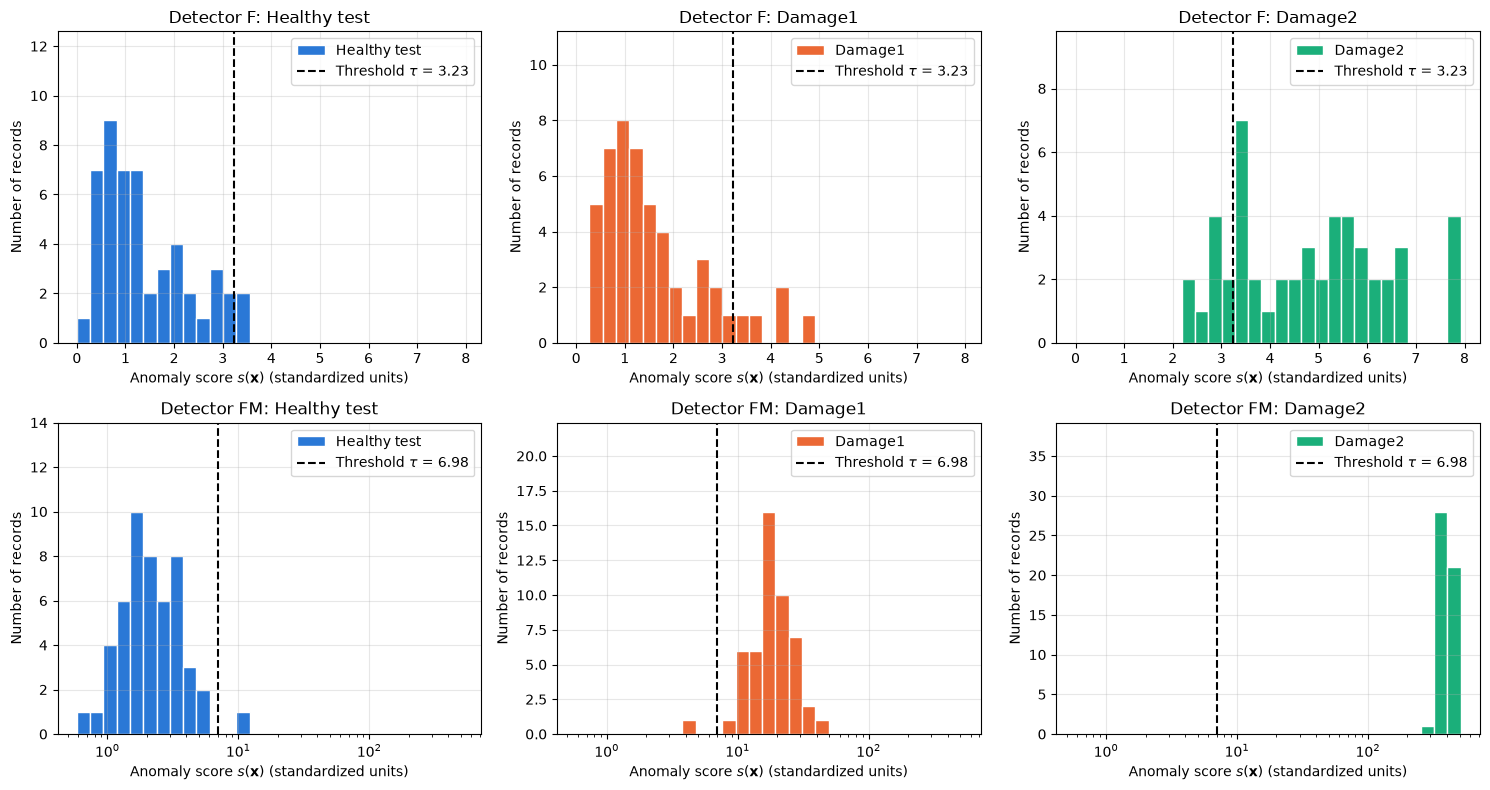

**Figure 4.** Histograms of the anomaly scores of the 50 healthy test, 50 damage1 and 50 damage2 records for Detector F (top, linear axis) and Detector FM (bottom, logarithmic axis), with the threshold $\tau$.

In [12]:
test_groups = [('Healthy test', 'test', COLORS['healthy']),
               ('Damage1', 'damage1', COLORS['damage1']),
               ('Damage2', 'damage2', COLORS['damage2'])]

# Logarithmic score axis only where the scores span several orders of magnitude
use_log_axis = {'F': False, 'FM': True}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

row = 0
for det in detectors:
    # Same bins for the three columns of a row, so that they can be compared
    all_scores = np.concatenate([scores[det]['test'], scores[det]['damage1'], scores[det]['damage2']])
    if use_log_axis[det]:
        bins = np.logspace(np.log10(all_scores.min()), np.log10(all_scores.max()), 30)
    else:
        bins = np.linspace(0, all_scores.max(), 30)

    for col in range(3):
        label, name, color = test_groups[col]
        ax = axes[row, col]
        counts, edges, patches = ax.hist(scores[det][name], bins=bins, color=color, edgecolor='white', label=label)
        ax.axvline(tau[det], color='black', linestyle='--', linewidth=1.5,
                   label=f'Threshold $\\tau$ = {tau[det]:.2f}')
        if use_log_axis[det]:
            ax.set_xscale('log')
        ax.set_xlabel('Anomaly score $s(\\mathbf{x})$ (standardized units)')
        ax.set_ylabel('Number of records')
        ax.set_title(f'Detector {det}: {label}')
        ax.grid(alpha=0.3)
        ax.set_ylim(0, 1.4 * counts.max())     # free space at the top for the legend
        ax.legend(loc='upper right')

    row = row + 1

fig.tight_layout()
show_figure(fig, 4, 'Histograms of the anomaly scores of the 50 healthy test, 50 damage1 and 50 damage2 '
            'records for Detector F (top, linear axis) and Detector FM (bottom, logarithmic axis), '
            'with the threshold $\\tau$.', 'B3_score_histograms.png')

**Umbral y falsas alarmas (Table 4).**

- **Detector F:** $\tau = 3.23$; 3 de los 50 registros sanos de test pasan el umbral (6 %).
- **Detector FM:** $\tau = 6.98$; 1 de los 50 (2 %).

Las dos tasas son mayores que el 1 % nominal, por tres razones:

- **Pocos registros de test.** El 1 % de 50 es medio registro; la tasa más baja distinta de cero que se puede medir es 1/50 = 2 %. Una sola falsa alarma ya da el doble del nominal.
- **Pocos registros de calibración.** El percentil 99 de 50 valores cae entre los dos puntajes más altos de calibración (Table 4: entre 2.94 y 3.51 para F, y entre 6.17 y 7.75 para FM). Así, el umbral depende de uno o dos registros extremos y cambia mucho de una muestra a otra. Como se vio en clase (Lecture 6, *A simple distance score ranks the damaged records well*), con 50 registros hay que esperar más de 1 % de falsas alarmas.
- **Muestras distintas.** Calibración y test son grupos distintos de 50 registros sanos. En F, los puntajes más altos del test (hasta 3.38) quedan algo por encima de $\tau$, y salen 3 falsas alarmas. La diferencia se explica por el tamaño de las muestras, no por un error del detector.

En la Figure 4 se ve además que, con F, los puntajes de damage1 se mezclan casi por completo con los sanos, mientras que con FM los de damage1 y damage2 quedan casi todos a la derecha de $\tau$.

<a id="b4"></a>
### B4. Performance Evaluation (10 pts)

**Conjuntos de evaluación.** Cada detector se prueba dos veces: con los 50 registros sanos de test junto con los 50 de damage1, y con los mismos 50 sanos junto con los 50 de damage2. El daño es la clase positiva (Lecture 6, *Name the positive class before reporting a metric*). Cada registro cae en una de las cuatro casillas de la matriz de confusión (Table 5).

**Table 5.** Outcomes of a detection; damage is the positive class.

| Actual / predicted | Healthy | Damage |
|---|---|---|
| Healthy | True negative (TN) | False positive (FP): false alarm |
| Damage | False negative (FN): missed damage | True positive (TP): detected damage |

**Métricas.** Con esos conteos se calculan (Ecs. 9 a 12):

$$\text{Recall} = \frac{TP}{TP+FN} \tag{9}$$

$$\text{FPR} = \frac{FP}{FP+TN} \tag{10}$$

$$\text{Precision} = \frac{TP}{TP+FP} \tag{11}$$

$$F_1 = \frac{2\,TP}{2\,TP+FP+FN} \tag{12}$$

- **Recall** (o tasa de verdaderos positivos, TPR): fracción de los registros dañados que se detectan.
- **FPR** (tasa de falsos positivos): fracción de los registros sanos que dan falsa alarma.
- **Precision:** de todas las alarmas, la fracción que corresponde a daño real. No está definida si no hay alarmas ($TP + FP = 0$).
- **$F_1$:** combina precisión y recall en un solo número (su media armónica).

**Curva ROC y AUC.** Si se mueve el umbral, cambian TP y FP. La curva ROC (*receiver operating characteristic*) dibuja el recall contra la FPR para todos los umbrales posibles; nuestro $\tau$ es un solo punto de la curva, el punto de operación (Lecture 6, *One score model produces many operating points*). El área bajo la curva (AUC) es (Ec. 13; Lecture 6, *AUC measures ranking across thresholds*):

$$\text{AUC} = P\left(s_+ > s_-\right) + \tfrac{1}{2}\,P\left(s_+ = s_-\right) \tag{13}$$

- $s_+$: puntaje de un registro dañado; $s_-$: puntaje de un registro sano.
- AUC es la probabilidad de que un registro dañado tenga un puntaje mayor que uno sano. Vale 1 si todos los dañados quedan por encima de todos los sanos y 0.5 si el puntaje no los distingue. No depende de $\tau$.

Los conteos y las métricas de las Ecs. 9 a 12 se calculan con NumPy; la curva ROC y el AUC, con `sklearn.metrics`.

In [13]:
def count_outcomes(healthy_scores, damage_scores, threshold):
    """Counts of the confusion matrix (Table 5) for a threshold; damage is the positive class."""
    TP = np.sum(damage_scores > threshold)
    FN = np.sum(damage_scores <= threshold)
    FP = np.sum(healthy_scores > threshold)
    TN = np.sum(healthy_scores <= threshold)
    return TP, FP, TN, FN


def auc_value(healthy_scores, damage_scores):
    """AUC (Eq. 13) of one test set: label 0 = healthy, label 1 = damage."""
    y_true = np.concatenate([np.zeros(len(healthy_scores)), np.ones(len(damage_scores))])
    y_score = np.concatenate([healthy_scores, damage_scores])
    return roc_auc_score(y_true, y_score)


SCENARIOS = ['damage1', 'damage2']

performance_rows = []
for det in detectors:
    for scen in SCENARIOS:
        TP, FP, TN, FN = count_outcomes(scores[det]['test'], scores[det][scen], tau[det])

        # Precision is undefined when nothing is flagged (Eq. 11)
        if TP + FP > 0:
            precision = TP / (TP + FP)
        else:
            precision = np.nan
        recall = TP / (TP + FN)                       # Eq. 9
        f1 = 2 * TP / (2 * TP + FP + FN)              # Eq. 12

        performance_rows.append({
            'Detector': det,
            'Scenario': scen.capitalize(),
            'TP (of 50)': TP,
            'FP (of 50)': FP,
            'Precision': precision,
            'Recall': recall,
            'F1': f1,
            'AUC': auc_value(scores[det]['test'], scores[det][scen]),
        })

performance_table = pd.DataFrame(performance_rows).set_index(['Detector', 'Scenario'])
show_table(performance_table, 6, 'Performance of each detector at the threshold $\\tau$: 50 healthy test '
           'records with 50 damage1 records, and the same 50 healthy test records with 50 damage2 records.',
           'B4_performance.csv')

**Table 6.** Performance of each detector at the threshold $\tau$: 50 healthy test records with 50 damage1 records, and the same 50 healthy test records with 50 damage2 records.

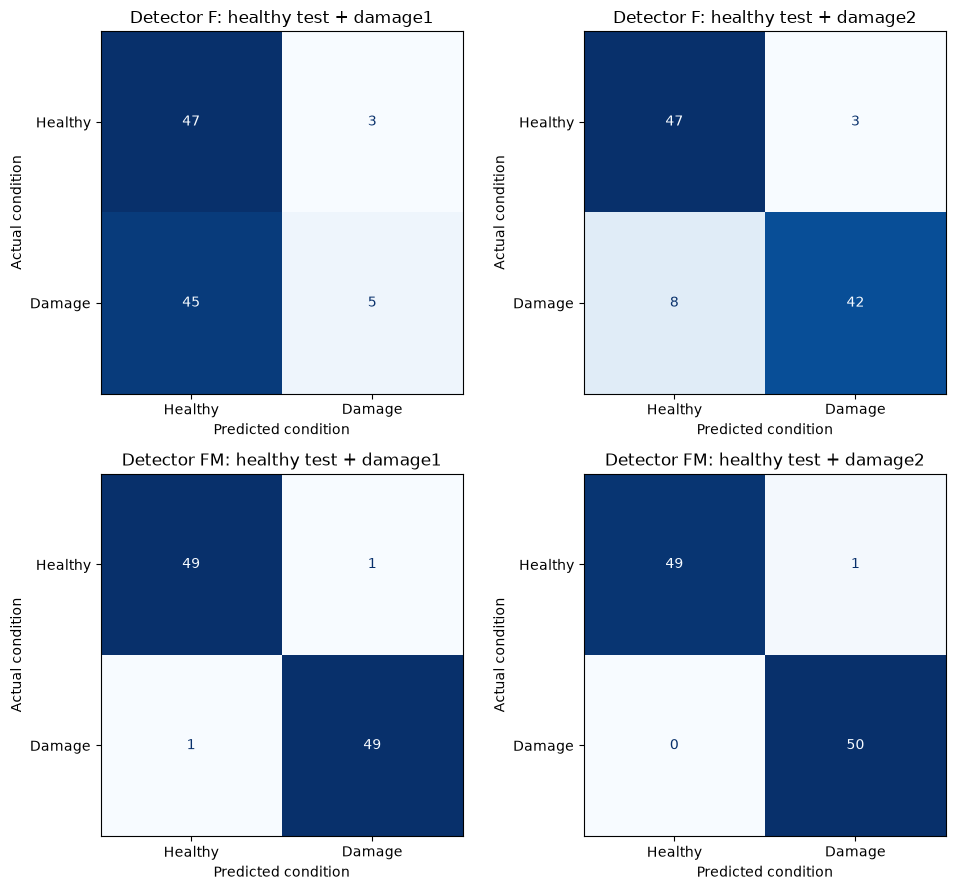

**Figure 5.** Confusion matrices at the threshold $\tau$. Rows: Detector F (top) and Detector FM (bottom). Columns: healthy test with damage1 (left) and with damage2 (right).

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

row = 0
for det in detectors:
    for col in range(2):
        scen = SCENARIOS[col]
        healthy_scores = scores[det]['test']
        damage_scores = scores[det][scen]

        # True labels (0 = healthy, 1 = damage) and predicted labels (score above the threshold)
        y_true = np.concatenate([np.zeros(len(healthy_scores)), np.ones(len(damage_scores))])
        y_score = np.concatenate([healthy_scores, damage_scores])
        y_pred = (y_score > tau[det]).astype(int)

        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        display_cm = ConfusionMatrixDisplay(cm, display_labels=['Healthy', 'Damage'])
        display_cm.plot(ax=axes[row, col], cmap='Blues', colorbar=False)
        axes[row, col].set_title(f'Detector {det}: healthy test + {scen}')
        axes[row, col].set_xlabel('Predicted condition')
        axes[row, col].set_ylabel('Actual condition')
    row = row + 1

fig.tight_layout()
show_figure(fig, 5, 'Confusion matrices at the threshold $\\tau$. Rows: Detector F (top) and Detector FM '
            '(bottom). Columns: healthy test with damage1 (left) and with damage2 (right).',
            'B4_confusion_matrices.png')

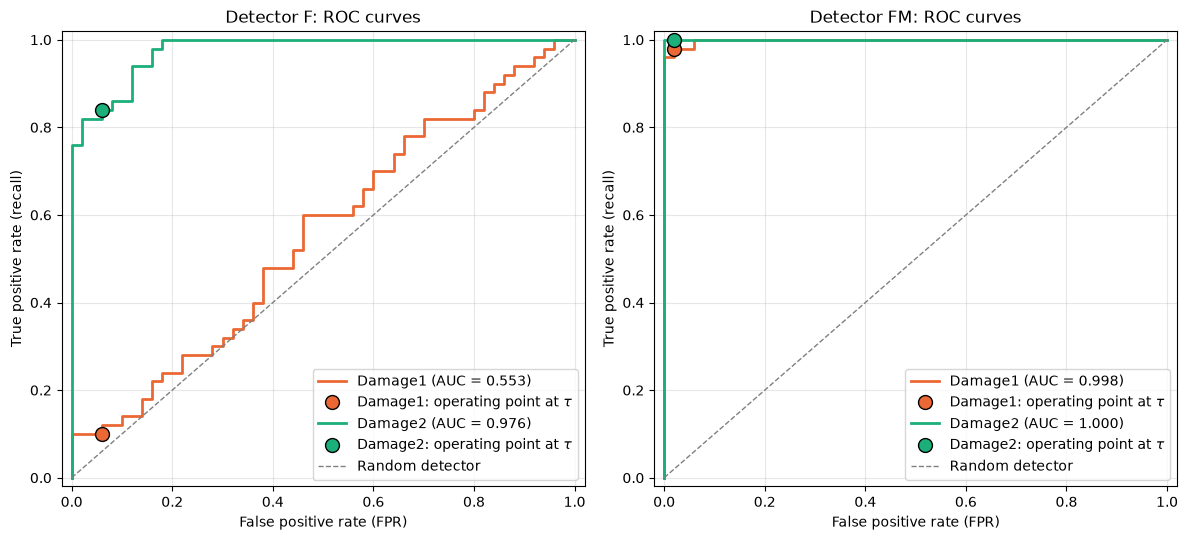

**Figure 6.** ROC curves of Detector F (left) and Detector FM (right) for both damage scenarios, with the AUC in the legend and the operating point at the threshold $\tau$ marked.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

col = 0
for det in detectors:
    ax = axes[col]
    for scen in SCENARIOS:
        healthy_scores = scores[det]['test']
        damage_scores = scores[det][scen]
        y_true = np.concatenate([np.zeros(len(healthy_scores)), np.ones(len(damage_scores))])
        y_score = np.concatenate([healthy_scores, damage_scores])

        # ROC curve over all thresholds and its AUC (Eq. 13)
        fpr, tpr, thresholds = roc_curve(y_true, y_score)
        auc = auc_value(healthy_scores, damage_scores)
        ax.plot(fpr, tpr, color=COLORS[scen], linewidth=2, label=f'{scen.capitalize()} (AUC = {auc:.3f})')

        # Operating point at the threshold tau (Eqs. 9 and 10)
        TP, FP, TN, FN = count_outcomes(healthy_scores, damage_scores, tau[det])
        ax.plot(FP / (FP + TN), TP / (TP + FN), marker='o', markersize=10, color=COLORS[scen],
                markeredgecolor='black', linestyle='none', label=f'{scen.capitalize()}: operating point at $\\tau$')

    ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Random detector')
    ax.set_xlabel('False positive rate (FPR)')
    ax.set_ylabel('True positive rate (recall)')
    ax.set_title(f'Detector {det}: ROC curves')
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')
    col = col + 1

fig.tight_layout()
show_figure(fig, 6, 'ROC curves of Detector F (left) and Detector FM (right) for both damage scenarios, '
            'with the AUC in the legend and the operating point at the threshold $\\tau$ marked.',
            'B4_roc_curves.png')

**¿Qué detector es mejor? (Table 6, Figures 5 y 6)**

- **Damage1:** FM es muy superior. Detecta 49 de 50 con 1 falsa alarma (recall 0.98, precisión 0.98, AUC 0.998). F detecta solo 5 de 50 (recall 0.10) y su AUC de 0.553 está cerca de 0.5: su puntaje casi no distingue damage1 de los sanos (en la Figure 6 su curva va pegada a la diagonal). La precisión de F (0.625) parece aceptable, pero sale de solo 8 alarmas (5 verdaderas y 3 falsas); leída junto con los conteos, F no sirve para damage1.
- **Damage2:** FM detecta los 50 registros con 1 falsa alarma (AUC 1.000). F detecta 42 de 50 (recall 0.84, AUC 0.976): el daño severo sí baja las frecuencias lo suficiente, pero 8 registros quedan por debajo de $\tau$.
- **Por qué FM es mejor:** incluye los MAC. Los MAC sanos casi no varían, así que el daño los mueve muchas desviaciones estándar sanas. Por ejemplo, en damage1 la media de $1-\mathrm{MAC}_2$ sube de $1.2\times10^{-4}$ a $1.9\times10^{-3}$, unas 15 desviaciones estándar sanas ($1.22\times10^{-4}$, Table 2). En cambio, las frecuencias de damage1 bajan menos de una desviación estándar sana. Al estandarizar, el puntaje de FM queda dominado por los MAC.

<a id="b5"></a>
### B5. Effect of the Number of Clusters (12 pts)

**Barrido de $k$.** Para el detector F se repite todo (k-means, puntajes, umbral con el percentil 99 de calibración y evaluación) para cada $k$ de 1 a 8.

**Referencia: detector de Mahalanobis (Phase 2).** Usa las mismas tres frecuencias y mide la distancia de cada registro a la media sana teniendo en cuenta la covarianza (Ec. 14; Lecture 5, *Mahalanobis distance scales each direction by its variability*):

$$D_M(\mathbf{x}) = \sqrt{\left(\mathbf{x}-\boldsymbol{\mu}_0\right)^{T}\,\boldsymbol{\Sigma}_0^{-1}\left(\mathbf{x}-\boldsymbol{\mu}_0\right)} \tag{14}$$

- $\mathbf{x}$: vector $(f_1, f_2, f_3)$ del registro, en Hz.
- $\boldsymbol{\mu}_0$, $\boldsymbol{\Sigma}_0$: media y matriz de covarianza de los 100 registros *fit*.
- $\boldsymbol{\Sigma}_0^{-1}$ escala cada dirección por su variabilidad sana: alejarse en una dirección en la que los sanos casi no varían cuenta mucho más que alejarse en la dirección en que más varían. La distancia euclidiana de la Ec. 7 no hace esta corrección.

Su umbral se fija con la misma regla: el percentil 99 de $D_M$ en los 50 registros de calibración.

In [16]:
# Results of Detector F for every k
sweep_rows = []
auc_k = {'damage1': [], 'damage2': []}
recall_k = {'damage1': [], 'damage2': []}

for k in K_VALUES:
    # Fit k-means on the fit records, score every subset, threshold from calibration (Eqs. 7 and 8)
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z_F['fit'])
    s_cal = anomaly_score(kmeans, Z_F['calibration'])
    s_test = anomaly_score(kmeans, Z_F['test'])
    threshold = np.percentile(s_cal, 99)

    row = {'Detector': f'k-means, k = {k}', 'Threshold': threshold,
           'FP (of 50 healthy test)': np.sum(s_test > threshold)}
    for scen in SCENARIOS:
        s_damage = anomaly_score(kmeans, Z_F[scen])
        TP, FP, TN, FN = count_outcomes(s_test, s_damage, threshold)
        recall_k[scen].append(TP / (TP + FN))
        auc_k[scen].append(auc_value(s_test, s_damage))
        row[f'Recall {scen}'] = TP / (TP + FN)
        row[f'AUC {scen}'] = auc_value(s_test, s_damage)
    sweep_rows.append(row)

# Mahalanobis detector (Eq. 14) with the same three frequencies, fitted on the same fit records
mu_fit = np.mean(X_fit[:, COLS_F], axis=0)
cov_fit = np.cov(X_fit[:, COLS_F], rowvar=False)
cov_inv = np.linalg.inv(cov_fit)


def mahalanobis_score(X_records):
    """Mahalanobis distance (Eq. 14) of every record to the healthy fit records."""
    distances = []
    for x in X_records:
        diff = x - mu_fit
        distances.append(np.sqrt(diff @ cov_inv @ diff))
    return np.array(distances)


m_cal = mahalanobis_score(X_cal[:, COLS_F])
m_test = mahalanobis_score(X_test[:, COLS_F])
tau_mahal = np.percentile(m_cal, 99)          # same 99th percentile rule (Eq. 8)

recall_mahal = {}
auc_mahal = {}
row = {'Detector': 'Mahalanobis', 'Threshold': tau_mahal, 'FP (of 50 healthy test)': np.sum(m_test > tau_mahal)}
for scen in SCENARIOS:
    m_damage = mahalanobis_score(subsets[scen][:, COLS_F])
    TP, FP, TN, FN = count_outcomes(m_test, m_damage, tau_mahal)
    recall_mahal[scen] = TP / (TP + FN)
    auc_mahal[scen] = auc_value(m_test, m_damage)
    row[f'Recall {scen}'] = recall_mahal[scen]
    row[f'AUC {scen}'] = auc_mahal[scen]
sweep_rows.append(row)

sweep_table = pd.DataFrame(sweep_rows).set_index('Detector')
show_table(sweep_table, 7, 'Detector F for k = 1 to 8 and the Mahalanobis distance detector with the same '
           'three frequencies: threshold, false alarms, recall at the threshold and AUC.', 'B5_k_sweep.csv')

**Table 7.** Detector F for k = 1 to 8 and the Mahalanobis distance detector with the same three frequencies: threshold, false alarms, recall at the threshold and AUC.

,Threshold,FP (of 50 healthy test),Recall damage1,AUC damage1,Recall damage2,AUC damage2
Detector,,,,,,
"k-means, k = 1",3.230,3,0.100,0.553,0.840,0.976
"k-means, k = 2",1.878,2,0.120,0.639,1.000,1.000
"k-means, k = 3",1.773,2,0.100,0.711,1.000,1.000
"k-means, k = 4",0.995,0,0.100,0.759,1.000,1.000
"k-means, k = 5",0.935,0,0.080,0.794,1.000,1.000
"k-means, k = 6",0.679,5,0.280,0.784,1.000,1.000
"k-means, k = 7",0.712,0,0.260,0.842,1.000,1.000
"k-means, k = 8",0.662,0,0.180,0.906,1.000,1.000
Mahalanobis,2.987,2,0.780,0.933,1.000,1.000


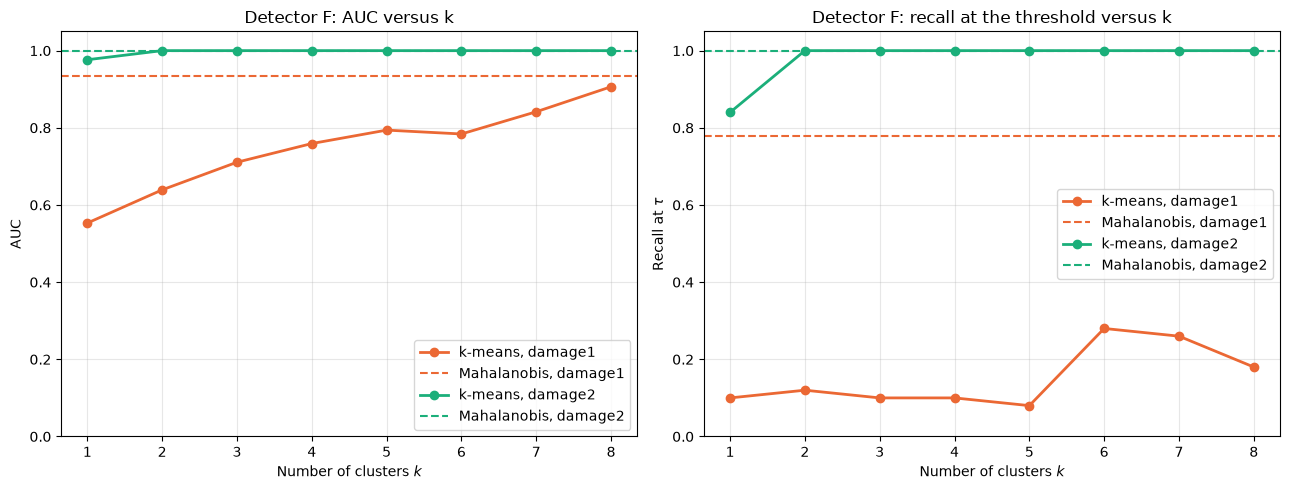

**Figure 7.** Detector F: AUC (left) and recall at the threshold $\tau$ (right) versus the number of clusters k, with the Mahalanobis distance detector on the same three frequencies as dashed reference lines.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for scen in SCENARIOS:
    # k-means results: one line per damage scenario
    axes[0].plot(K_VALUES, auc_k[scen], marker='o', linewidth=2, color=COLORS[scen],
                 label=f'k-means, {scen}')
    axes[1].plot(K_VALUES, recall_k[scen], marker='o', linewidth=2, color=COLORS[scen],
                 label=f'k-means, {scen}')

    # Mahalanobis results: horizontal reference lines
    axes[0].axhline(auc_mahal[scen], color=COLORS[scen], linestyle='--', linewidth=1.5,
                    label=f'Mahalanobis, {scen}')
    axes[1].axhline(recall_mahal[scen], color=COLORS[scen], linestyle='--', linewidth=1.5,
                    label=f'Mahalanobis, {scen}')

axes[0].set_ylabel('AUC')
axes[0].set_title('Detector F: AUC versus k')
axes[1].set_ylabel('Recall at $\\tau$')
axes[1].set_title('Detector F: recall at the threshold versus k')
axes[0].legend(loc='lower right')
axes[1].legend(loc='center right')

for ax in axes:
    ax.set_xlabel('Number of clusters $k$')
    ax.set_xticks(K_VALUES)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 7, 'Detector F: AUC (left) and recall at the threshold $\\tau$ (right) versus the number of '
            'clusters k, with the Mahalanobis distance detector on the same three frequencies as dashed '
            'reference lines.', 'B5_effect_of_k.png')

**Tendencias con $k$ (Table 7, Figure 7).**

- **AUC:** para damage1 sube con $k$, de 0.553 con $k = 1$ a 0.906 con $k = 8$. Para damage2 pasa de 0.976 a 1.000 desde $k = 2$.
- **Recall con $\tau$:** para damage1 se queda bajo con todos los $k$ (de 0.08 a 0.28, es decir, de 4 a 14 de 50). Para damage2 sube de 0.84 a 1.00 desde $k = 2$.
- **Mahalanobis:** recall de 0.78 en damage1 (39 de 50) con 2 falsas alarmas y AUC de 0.933; en damage2, recall y AUC de 1.00. Es mejor que k-means con cualquier $k$.

**Por qué sube el AUC.** La nube sana de frecuencias es casi una línea ($\rho_{12} = 0.985$, Figure 1). Con un solo centroide, el puntaje (Ec. 7) mide sobre todo cuánto se aleja el registro *a lo largo* de la línea, que es justo la dirección en que los sanos más varían. Damage1 no se mueve a lo largo de la línea sino *hacia afuera* de ella: $f_2$ baja más que $f_1$ y $f_3$ (−3.2 % frente a −1.3 % y −1.6 %), y en la Figure 1 sus puntos quedan un poco por debajo de la nube sana. Con más clusters, los centroides se reparten sobre la línea (Figure 3) y el puntaje pasa a medir la distancia a la línea, que es la dirección en que se mueve el daño. Por eso los registros dañados quedan mejor ordenados por encima de los sanos.

**Por qué el recall no sigue al AUC.** El AUC mide el orden de los puntajes con todos los umbrales posibles; el recall usa un solo umbral, el percentil 99 de calibración. Ese umbral lo fijan uno o dos registros sanos extremos, y la mayoría de los registros de damage1 se aleja de la línea menos que ellos. Quedan por encima de la mayoría de los sanos (AUC alto), pero por debajo de $\tau$ (recall bajo).

**Por qué Mahalanobis es mejor.** $\boldsymbol{\Sigma}_0^{-1}$ (Ec. 14) usa la correlación: como la nube es muy angosta en la dirección perpendicular a la línea, un alejamiento pequeño en esa dirección ya da una distancia grande. k-means con distancia euclidiana solo se acerca a ese comportamiento agregando clusters, y sin llegar a él.

**Por qué este barrido no sirve para elegir $k$.** El barrido mide el desempeño con registros dañados. Un puente en servicio no tiene registros de daño (con suerte, nunca los tendrá), así que en la práctica no se puede hacer. Además, elegir el $k$ que mejor detecta damage1 sería ajustar el detector con los mismos datos con que se evalúa: el desempeño reportado sería optimista y no diría nada sobre un daño distinto. Por eso en B2 $k$ se eligió solo con registros sanos.

<a id="b6"></a>
### B6. Damage Severity (8 pts)

**Puntajes por escenario.** La Figure 8 muestra los puntajes del detector FM con el $k$ elegido ($k = 1$, Ec. 7) para los registros sanos de test, damage1 y damage2, con el umbral $\tau$. El eje es logarítmico porque los puntajes van de menos de 1 a varios cientos. La Table 8 da la media de cada grupo.

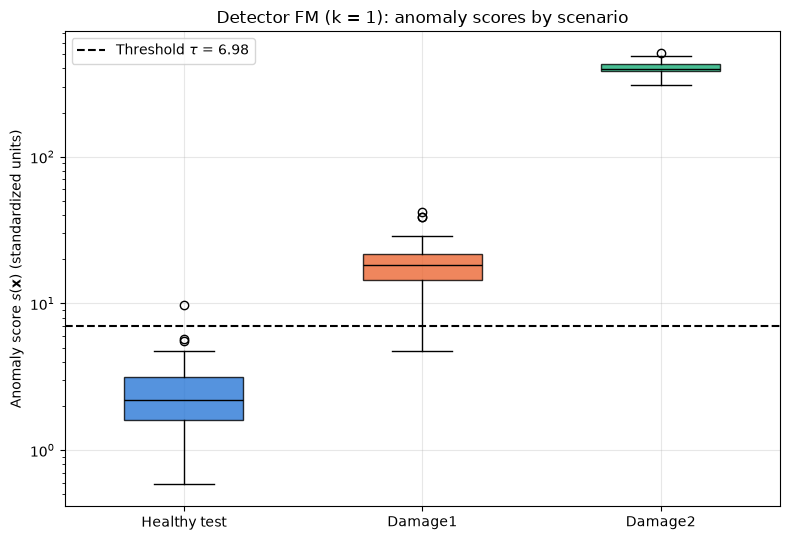

**Figure 8.** Box plot of the Detector FM anomaly scores of the 50 healthy test, 50 damage1 and 50 damage2 records, with the threshold $\tau$ (logarithmic axis).

**Table 8.** Detector FM: mean, minimum and maximum anomaly score of each group.

,Records,Mean score,Minimum score,Maximum score
Group,,,,
Healthy test,50,2.53,0.58,9.73
Damage1,50,19.33,4.77,41.75
Damage2,50,401.55,309.49,510.80


In [18]:
box_groups = [('Healthy test', 'test'), ('Damage1', 'damage1'), ('Damage2', 'damage2')]

fig, ax = plt.subplots(figsize=(8, 5.5))

box_data = []
box_labels = []
for label, name in box_groups:
    box_data.append(scores['FM'][name])
    box_labels.append(label)

boxes = ax.boxplot(box_data, tick_labels=box_labels, patch_artist=True, widths=0.5)
group_colors = [COLORS['healthy'], COLORS['damage1'], COLORS['damage2']]
for n in range(3):
    boxes['boxes'][n].set_facecolor(group_colors[n])
    boxes['boxes'][n].set_alpha(0.8)
for median_line in boxes['medians']:
    median_line.set_color('black')

ax.axhline(tau['FM'], color='black', linestyle='--', linewidth=1.5, label=f'Threshold $\\tau$ = {tau["FM"]:.2f}')
ax.set_yscale('log')
ax.set_ylabel('Anomaly score $s(\\mathbf{x})$ (standardized units)')
ax.set_title(f'Detector FM (k = {K_CHOSEN["FM"]}): anomaly scores by scenario')
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
show_figure(fig, 8, 'Box plot of the Detector FM anomaly scores of the 50 healthy test, 50 damage1 and '
            '50 damage2 records, with the threshold $\\tau$ (logarithmic axis).', 'B6_score_boxplot.png')

# Mean score of each group, with its minimum and maximum
score_rows = []
for label, name in box_groups:
    score_rows.append({'Group': label,
                       'Records': len(scores['FM'][name]),
                       'Mean score': np.mean(scores['FM'][name]),
                       'Minimum score': np.min(scores['FM'][name]),
                       'Maximum score': np.max(scores['FM'][name])})
score_table = pd.DataFrame(score_rows).set_index('Group')
show_table(score_table, 8, 'Detector FM: mean, minimum and maximum anomaly score of each group.',
           'B6_mean_scores.csv', precision=2)

**Media del puntaje por grupo (Table 8).** Sanos de test: 2.53; damage1: 19.33; damage2: 401.55. Sí, el puntaje ordena los escenarios por severidad: la media de damage1 es unas 8 veces la de los sanos y la de damage2, unas 160 veces. Además, los puntajes de damage1 y damage2 no se traslapan: el mayor de damage1 (41.75) es mucho menor que el menor de damage2 (309.49).

**Corrimiento medio de cada característica.** Para ver qué características empujan el puntaje se calcula la media de cada característica estandarizada en los registros dañados (Ec. 15). Como los registros *fit* tienen media cero después de estandarizar, este valor es directamente el corrimiento del escenario, medido en desviaciones estándar sanas:

$$\Delta_j = \frac{1}{M}\sum_{i=1}^{M} z_{ij} \tag{15}$$

- $M = 50$ registros del escenario de daño.
- $z_{ij}$: característica $j$ del registro $i$, estandarizada con los registros *fit* (Ec. 2).

El eje vertical de la Figure 9 es *symlog*: lineal entre −1 y 1 y logarítmico fuera de ese rango, para que quepan en la misma gráfica corrimientos menores que 1 y de cientos.

**Table 9.** Mean standardized shift of each feature for damage1 and damage2 (in standard deviations of the healthy fit records).

,Damage1,Damage2
Feature,,
f1,-0.34,-1.38
f2,-0.89,-4.05
f3,-0.45,-1.37
MAC1,-4.97,-160.11
MAC2,-14.63,-272.05
MAC3,-10.86,-246.22


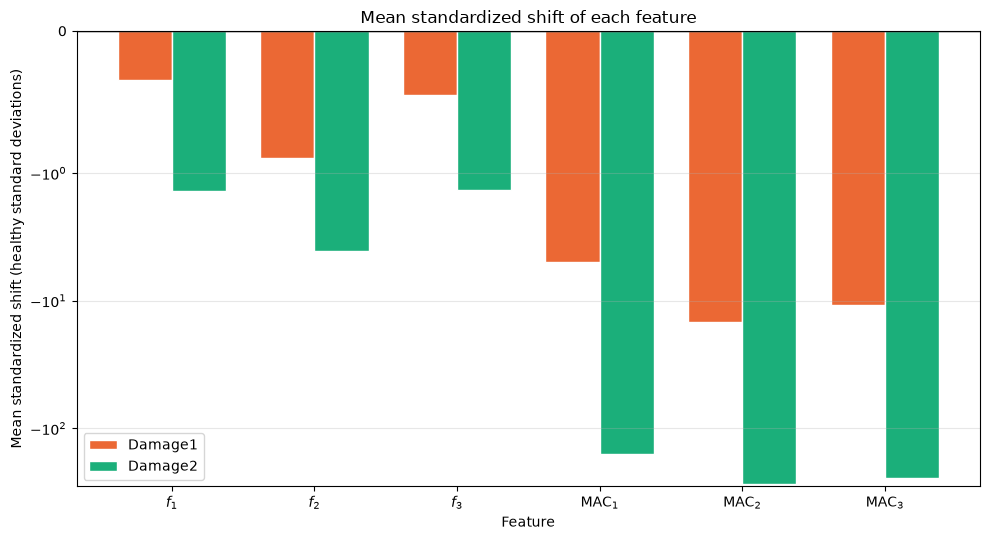

**Figure 9.** Mean standardized shift of each of the six features for damage1 and damage2 (symmetric logarithmic axis: linear between -1 and 1).

In [19]:
feature_labels = ['$f_1$', '$f_2$', '$f_3$', 'MAC$_1$', 'MAC$_2$', 'MAC$_3$']
table_labels = ['f1', 'f2', 'f3', 'MAC1', 'MAC2', 'MAC3']

# Mean standardized shift of each feature (Eq. 15)
shift = {}
for scen in SCENARIOS:
    shift[scen] = np.mean(Z_FM[scen], axis=0)

shift_table = pd.DataFrame({'Damage1': shift['damage1'], 'Damage2': shift['damage2']},
                           index=pd.Index(table_labels, name='Feature'))
show_table(shift_table, 9, 'Mean standardized shift of each feature for damage1 and damage2 '
           '(in standard deviations of the healthy fit records).', 'B6_feature_shifts.csv', precision=2)

# Grouped bar chart: six features, one bar per damage scenario
positions = np.arange(6)
bar_width = 0.38

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(positions - bar_width / 2, shift['damage1'], width=bar_width, color=COLORS['damage1'], edgecolor='white', label='Damage1')
ax.bar(positions + bar_width / 2, shift['damage2'], width=bar_width, color=COLORS['damage2'], edgecolor='white', label='Damage2')
ax.axhline(0, color='black', linewidth=1)

ax.set_yscale('symlog', linthresh=1)
ax.set_xticks(positions)
ax.set_xticklabels(feature_labels)
ax.set_xlabel('Feature')
ax.set_ylabel('Mean standardized shift (healthy standard deviations)')
ax.set_title('Mean standardized shift of each feature')
ax.grid(alpha=0.3, axis='y')
ax.legend()

fig.tight_layout()
show_figure(fig, 9, 'Mean standardized shift of each of the six features for damage1 and damage2 '
            '(symmetric logarithmic axis: linear between -1 and 1).', 'B6_feature_shifts.png')

**Qué empuja el puntaje (Table 9, Figure 9).** Los MAC. En damage1, los MAC se corren entre −5.0 y −14.6 desviaciones estándar sanas y las frecuencias entre −0.3 y −0.9. En damage2, los MAC se corren entre −160 y −272 y las frecuencias entre −1.4 y −4.0. Con $k = 1$ el centroide está en el origen, así que el puntaje es $s = \sqrt{z_1^2 + z_2^2 + \dots + z_6^2}$ y cada característica pesa con el cuadrado de su corrimiento: los MAC aportan casi todo.

**¿Puede el detector distinguir damage1 de damage2?** En estos datos, sí: los puntajes de los dos escenarios no se traslapan, así que un segundo umbral entre 42 y 309 los separaría. Pero en la práctica hay que tener cuidado:

- El detector se entrenó solo con registros sanos. Su respuesta es "anómalo" o "no anómalo"; no sabe qué puntaje corresponde a qué severidad. Para fijar niveles de severidad harían falta registros de daño conocido, que un puente en servicio no tiene.
- El puntaje es tan grande porque la dispersión sana de los MAC es muy pequeña en estos datos. Su valor depende de esa dispersión, no solo del tamaño del daño.
- El puntaje no dice dónde está el daño ni de qué tipo es.

Por eso el puntaje sirve para priorizar inspecciones (un puntaje más alto indica un cambio mayor respecto de lo sano), pero la evaluación del daño sigue requiriendo una inspección.

<a id="part-c"></a>
## Part C: Engineering Insights (15 pts)

<a id="c1"></a>
### C1. Detector Recommendation (5 pts)

<a id="c2"></a>
### C2. From Simulation to the Field (5 pts)

<a id="c3"></a>
### C3. A Bridge with Several Normal States (5 pts)

<a id="ai-note"></a>
## Use of Generative AI

Each group member describes their own use of AI below.

### Amilcar Diaz

### Alexander Jordan